In [3]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [ ]:
# 1 . Import Database/Data

In [6]:
#import database

conn = sqlite3.connect('customer_churn.db')

sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type ='table'
        """

tables = pd.read_sql(sql_query, conn)


#create datframe for each table
for table_name in tables['name']:
 df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into datafra
 globals()[f"df_{table_name}"] = df # Create dynamic datafram
 print(f"Created dataframe: df_{table_name}")

conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [7]:
conn = sqlite3.connect('customer_churn.db')
for table_name in tables['name']:
 print(f"\nTable Name: {table_name}")
 # Get column information
 columns_query = f"PRAGMA table_info({table_name});" # PRAGMA is a special command in SQLite used to:
                                                     # inspect db information, control db settings, retrieve metadata about tables
 columns = pd.read_sql(columns_query, conn)
 print("Columns:")
 print(columns['name'].tolist())
# Close connection
conn.close()



Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [ ]:
# 2 . Data Cleaning

In [13]:
df_db_customer.head() 

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [11]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 2.5+ KB


In [ ]:
# a. rename col - name to customer_name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values (using existing data) - country

In [12]:
# a. rename col - name to customer_name
df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace= True)


In [16]:
# b. drop columns - interest and pincode

# df_db_customer.drop(df_db_customer.columns[-2:], axis=1) #using -ve indexing
# df_db_customer.drop(df_db_customer.columns[6:], axis=1)  #using +ve indexing
df_db_customer.drop(columns=['interests', 'pincode'], inplace=True) # using col name


KeyError: "['interests', 'pincode'] not found in axis"

In [21]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.8 KB


In [20]:
# c. change data type - dob = object to datatime

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [24]:
# d. data standardization - gender

#df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [25]:
df_db_customer['gender'].unique()

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [27]:
# e. fix missing values - country
#df_db_customer['country'].isna()
df_db_customer[df_db_customer['country'].isna()]


0     False
1     False
2     False
3     False
4     False
5      True
6     False
7     False
8      True
9     False
10    False
11    False
12     True
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
Name: country, dtype: bool

In [31]:
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [32]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [33]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,India,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,Nepal,Kathmandu
9,Nepal,Kathmandu


In [34]:
df_db_subscription.head() # subcription table


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [35]:
df_db_subscription.tail() # subcription table

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
16,0020-JDNXP,2022-01-19,Organic,2024-01-19,Premium,Annual,NaN,NaN,20.99,550,62
17,0021-IKXGC,2021-07-07,Paid,2025-07-07,Standard,Annual,NaN,NaN,13.99,840,27
18,0022-TCJCI,2023-09-14,Refferal,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99
19,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,NaN,NaN,22.99,1955,7
20,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,NaN,NaN,13.99,790,47


In [38]:
df_db_subscription.info() 


<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 2.7 KB


In [37]:
# change data type to date - subscription_start_date , renewal_date, cancellation_d

date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 2.7 KB


In [39]:
df_db_support.head() # support table


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [40]:
df_db_support.head() # support table


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [41]:
# drop columns
df_db_support.drop(columns=['col_1', 'comment'], inplace=True)


In [42]:
# change data type to date - complaint_date

df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()


<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 519.0 bytes


In [ ]:
# 3 .  Feature Engineerin and Data Analysis

In [53]:
# create a new col using existing col - churn flag

# Customer is churned if cancellation_date is not null
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [54]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [52]:

df = (df_db_subscription
 .merge(df_db_customer, on = 'customerid', how= 'left')
 .merge(df_db_support, on = 'customerid', how= 'left') )


In [51]:
df_db_subscription.shape

(21, 12)

In [50]:
df.shape

(23, 20)

In [56]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())


df_db_subscription unique value: 21


In [57]:
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())


df_db_customer unique value: 21


In [58]:
print('df_db_support unique value:', df_db_support['customerid'].nunique())


df_db_support unique value: 7


In [59]:
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_support all value: 9


In [60]:
df_db_support
#0	0003-MKNFE	2024-08-28	N	60  same customer but 2 entries 
#1	0003-MKNFE	2024-08-28	Y	10

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [63]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform("count")


In [66]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

,customerid,complaint_date,escalations,csat_score,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,1
5,0017-IUDMW,2024-04-10,Y,25,1
1,0003-MKNFE,2024-08-28,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2
6,0019-EFAEP,2024-09-27,Y,30,1
4,0013-SMEOE,2024-11-01,N,30,1
3,0013-MHZWF,2025-03-18,N,90,1


In [67]:
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_support all value: 7


In [68]:
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after
df = (df_db_subscription
 .merge(df_db_customer, on = 'customerid', how= 'left')
 .merge(df_db_support, on = 'customerid', how= 'left') )


In [69]:
df.shape

(21, 21)

In [70]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

In [ ]:

# Data Analysis


In [71]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [74]:
# 1. Churn Rate 

churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), "%")


Churn Rate =  28.57 %


In [73]:
# 2. Retenion Rate

retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")


Retention Rate =  71.43 %


In [77]:
# 3. Churn by Plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index())
print(churn_by_plan)


  plan_type  churn_flag
0     Basic       60.00
1   Premium       14.29
2  Standard       22.22


In [83]:
# 5. ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))


ARPU =  18.85


In [84]:
# 6. Avg Customer Tenure
# count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()
df['tenure_days'] = np.where(
 df['cancellation_date'].notna(),
 (df['cancellation_date'] - df['subscription_start_date']).dt.days,
 (today - df['subscription_start_date']).dt.days
)
avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure),0)


Avg Tenure (Days) =  1590 0


In [90]:
# 7. Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K') =", revenue_at_risk, "K")

Revenue at Risk (Rs 'K') = 73.94 K


In [89]:
# 8. Esclation Rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Esclation Rate = ", round(escalation_rate, 2), "%")


Esclation Rate =  19.05 %


In [91]:
# 9. Avg Complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Compliants Per User = ", round(avg_complaints, 2))

Avg Compliants Per User =  0.43


In [92]:
# 10. Correlation Esclation vs Churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)
corr_df = df[['escalations', 'churn_flag']].dropna()
correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))

Correlation between esclation vs churn is =  0.77


In [94]:
# 11. Create a column using existing col - Churn risk
conditions = [
 (df['churn_score'] < 50),
 (df['churn_score'] >= 50) & (df['churn_score'] < 70),
 (df['churn_score'] >= 70)
]
choices = ['low', 'med', 'high']
df['churn_risk'] = np.select(conditions, choices, default='unkown')

In [ ]:
# 4. Visualization using Matplotlib

In [95]:
# best practice to create a copy then work on it
df_visual = df.copy()


In [96]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='str')

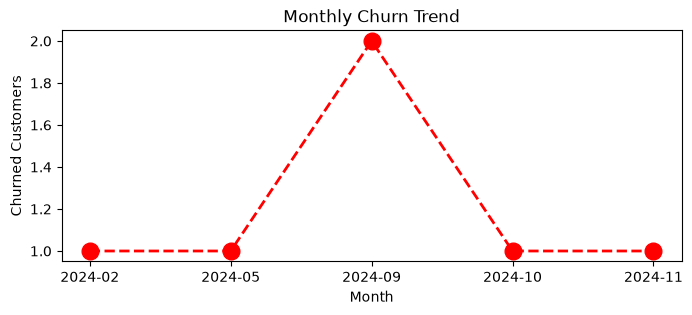

In [102]:
# 4.1 Monthly Churn Trend (Time Series KPI)
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')
churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()
plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='r', marker='o',linestyle='dashed',linewidth=2,markersize=12)
plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()


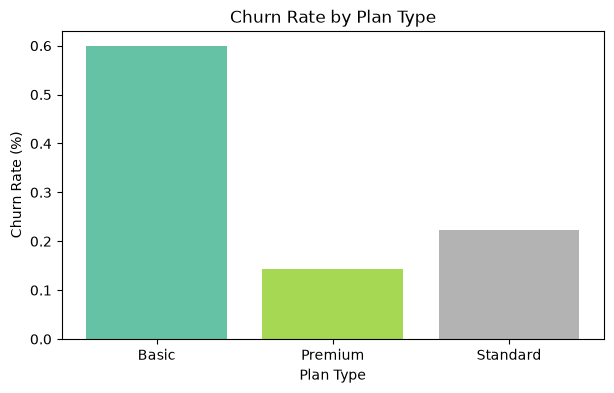

In [105]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()
# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))
plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()


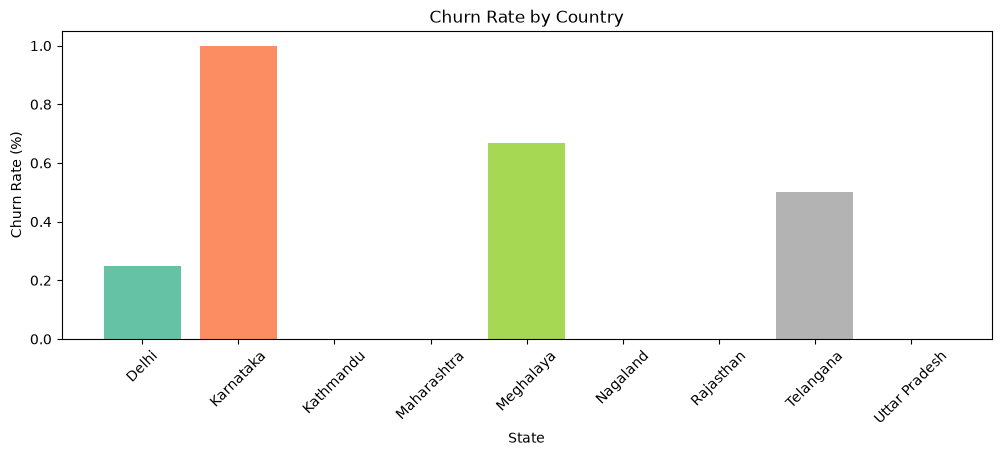

In [108]:
# 4.3 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean()
# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan))) 
plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.title('Churn Rate by Country')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Visulaization using Seaborn

In [ ]:
# Heatmap (Correlation Matrix)

In [109]:
# encoding - convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [111]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [112]:
# remove warnings
import warnings 
warnings.filterwarnings("ignore")


In [128]:
# incorrect method of encoding - as numbers are not assigned based on priority

df_encoded = df_visual[['plan_type', 'contract_type',  'churn_risk','churn_score', 'churn_flag','escalations']]
categorial_cols = ['plan_type', 'contract_type', 'churn_risk']
for col in categorial_cols:
 df_encoded[col] = df_encoded[col].astype('category').cat.codes


<Axes: >

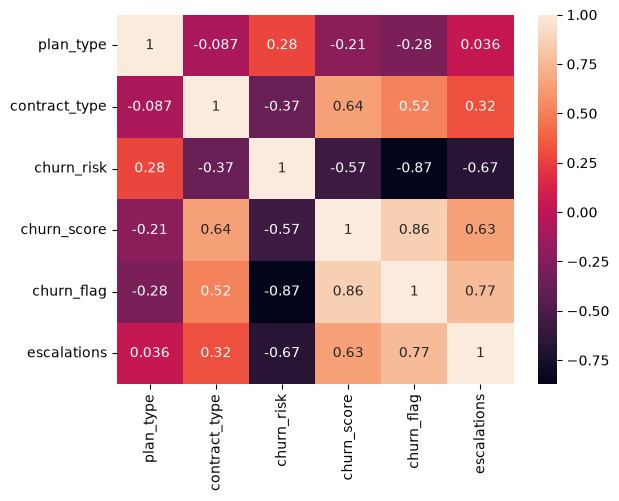

In [129]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

In [130]:
print("plan_type :", df_visual["plan_type"].dropna().unique().tolist())
print("contract_type :", df_visual["contract_type"].dropna().unique().tolist())
print("churn_risk :", df_visual["churn_risk"].dropna().unique().tolist())

plan_type : ['Standard', 'Premium', 'Basic']
contract_type : ['Annual', 'Monthly']
churn_risk : ['low', 'high', 'med']


In [131]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag','churn_risk','escalations']]
order_mappings = {
 'plan_type' : ['Basic', 'Standard', 'Premium'], #0,1,2
 'contract_type' : ['Monthly', 'Annual'],
 'churn_risk': ['low', 'med', 'high']
}
for col, order in order_mappings.items():
 df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order,ordered=True).codes

In [132]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [133]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

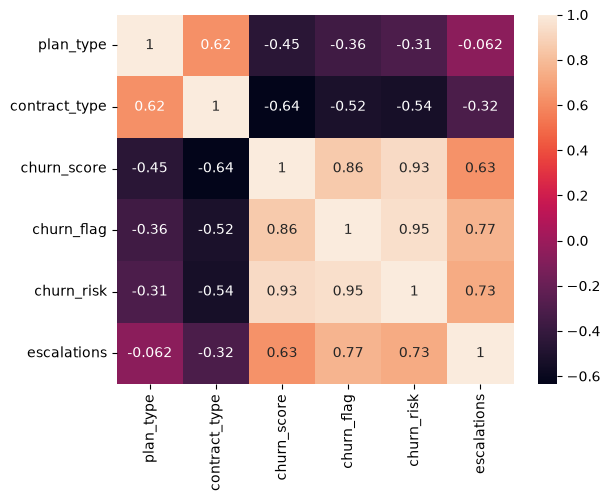

In [135]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)
#sns.heatmap(df_encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)

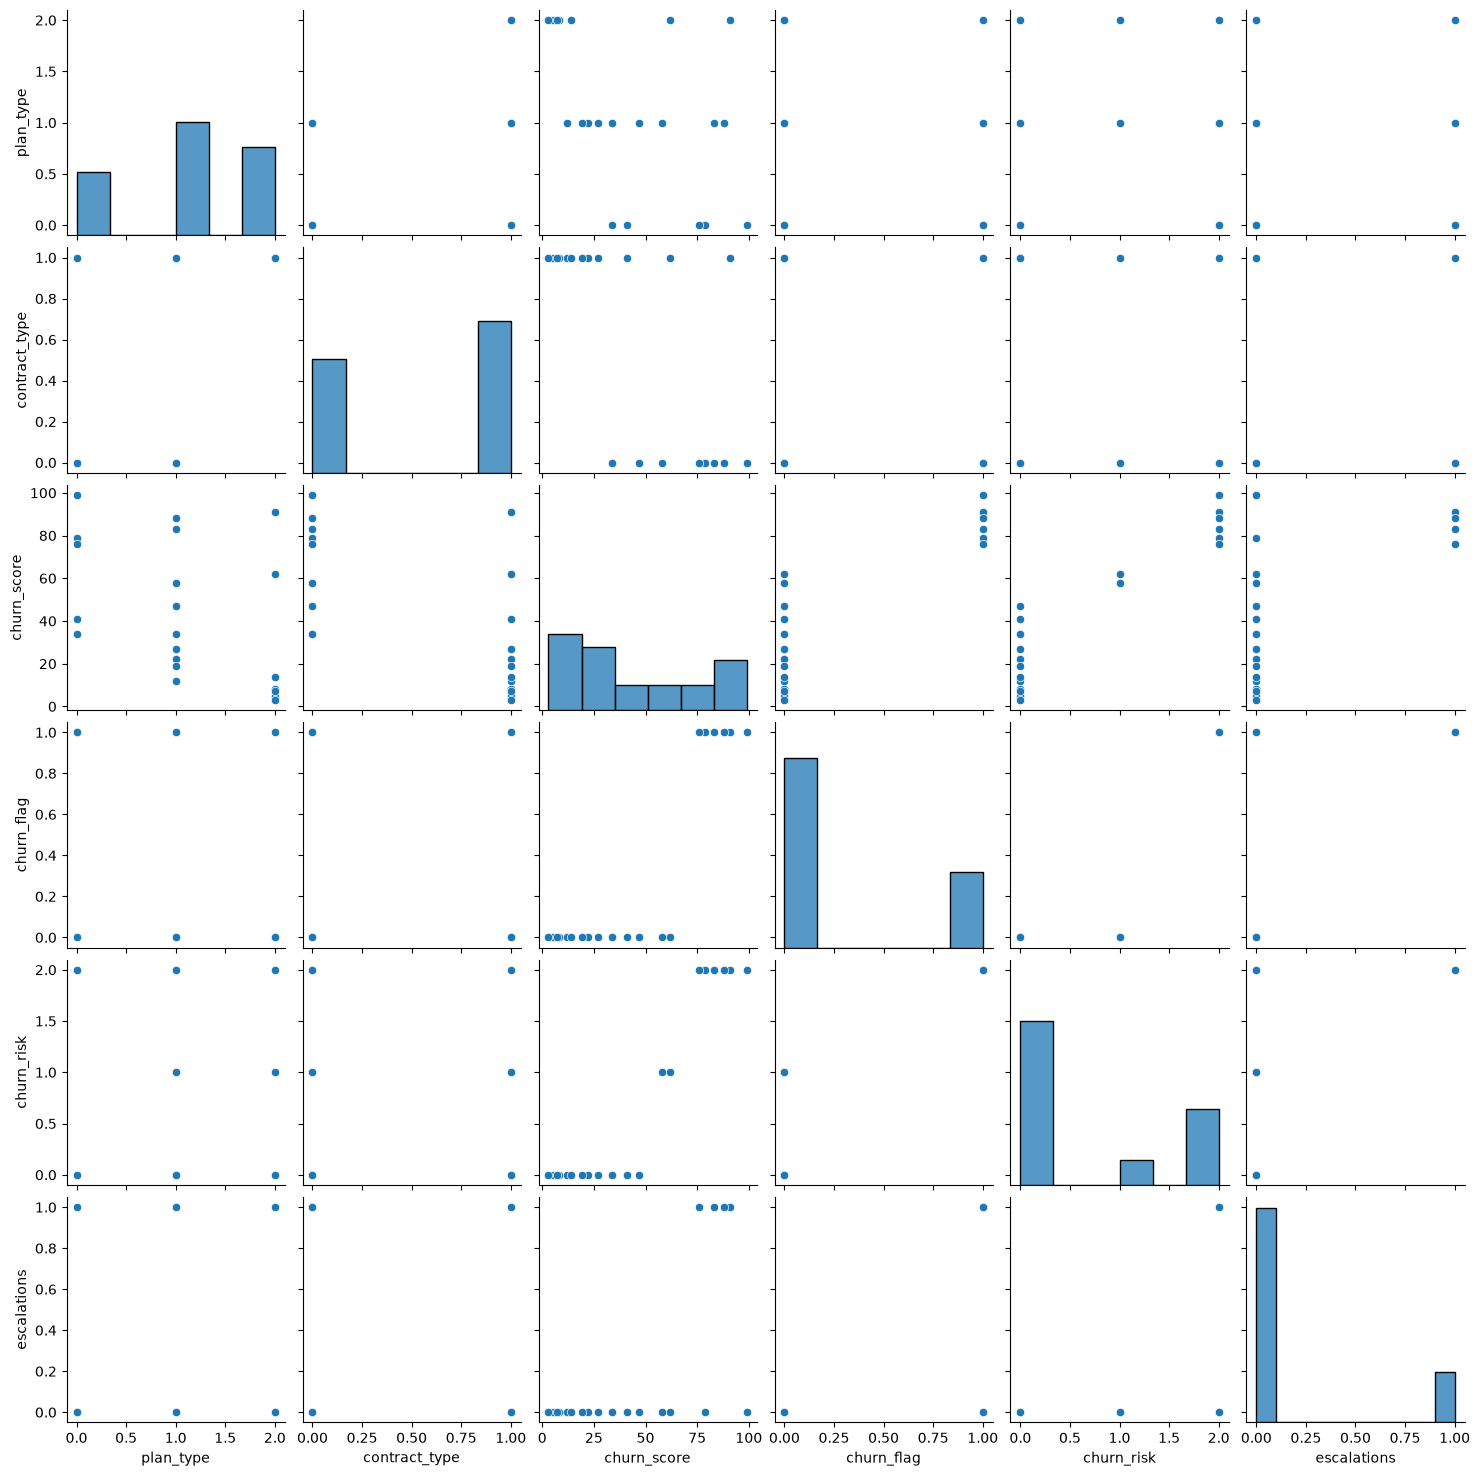

In [136]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)


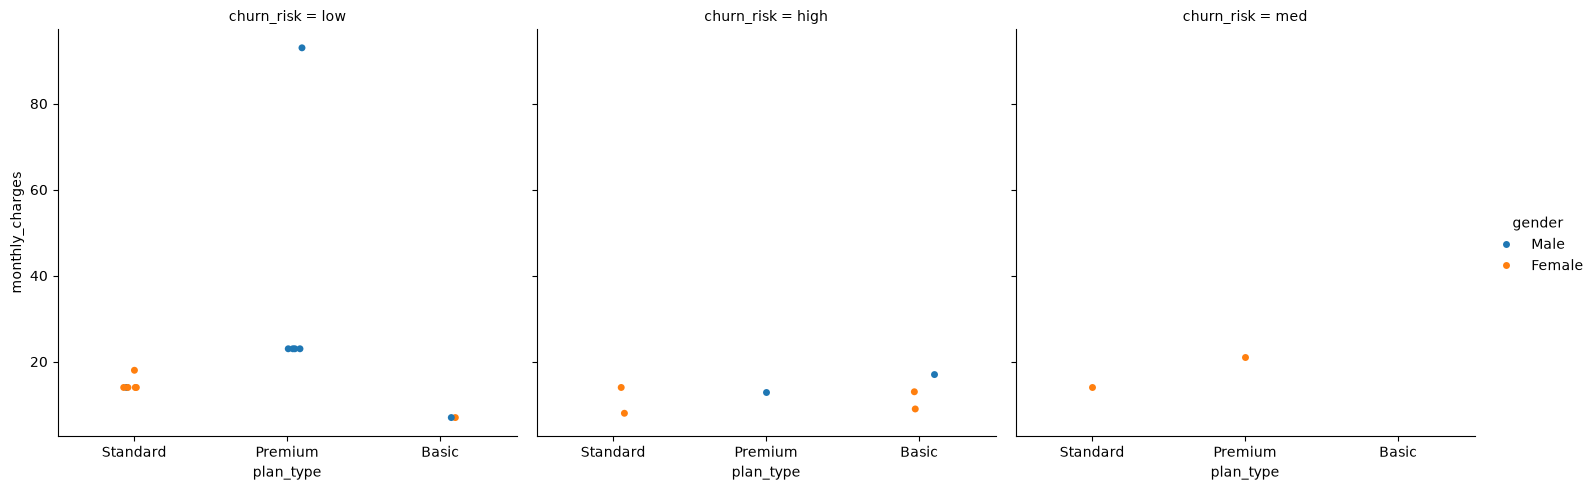

In [137]:
# catplt/Facegrid plot - multi-dim comparison
sns.catplot(data=df_visual,
 x='plan_type',
 y='monthly_charges',
 hue='gender',
 col='churn_risk')


In [ ]:
#Pivot table

In [138]:
pd.pivot_table(
 df_visual,
 index='plan_type',
 values='churn_flag',
 aggfunc = 'mean'
)


,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [139]:
# pivot table using multiple cols and agg type
pd.pivot_table(
 df_visual,
 index='plan_type',
 values=['monthly_charges', 'customerid', 'churn_flag'],
 aggfunc = {
 'monthly_charges' : 'sum',
 'customerid' : 'nunique',
 'churn_flag' : 'mean'
 }
)


,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [ ]:
# Project Completed Here.
